# 04 — Probability for learning

| | |
| --- | --- |
| **Prerequisites** | Notebooks 00–03: tensors, sums and broadcasting, derivatives, gradient descent |
| **You will learn** | Discrete and continuous distributions; expectation, variance, and the law of large numbers; why we work with log-probabilities; likelihood and maximum likelihood estimation; how squared error and cross-entropy losses follow from likelihood; entropy, cross-entropy, and KL divergence |
| **Estimated time** | About 3 hours |
| **Compute** | CPU only, under a minute. |

## Setup

In [1]:
# Setup: make the course helpers importable and record the environment.
import sys
from pathlib import Path

try:
    import dlcourse
except ImportError:  # running without `uv sync`, e.g. on Colab after cloning the repo
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dlcourse").is_dir())
    sys.path.insert(0, str(root))
    import dlcourse

import matplotlib.pyplot as plt
import torch

from dlcourse import check, check_close, check_shape, passed, set_seed
from dlcourse.plotting import setup_style

setup_style()
device = dlcourse.describe_environment()
set_seed(0)

Python  3.12.13 (Darwin arm64)
PyTorch 2.14.1
CUDA available: False
MPS available:  True
Selected device: mps


In [2]:
import math

from torch.distributions import Bernoulli, Categorical, Normal

from dlcourse.plotting import COLORS

Everything in this notebook runs on the CPU, and many computations use `float64` so that rounding does not blur the comparisons. (Apple's MPS device does not support `float64`, which is one more reason to stay on the CPU here.)

## Motivating problem

Notebook 03 showed how to *minimize* a loss: follow the negative gradient downhill. But it took the loss as given. Where do loss functions come from? Why do people fit lines by minimizing *squared* error rather than absolute error or the fourth power? Why is the standard classification loss called "cross-entropy", and what does it have to do with entropy?

The answer, which this notebook builds step by step, is that the usual losses are **negative log-likelihoods**: they measure how improbable a model finds the observed data. Minimizing a loss means choosing the model under which the data is most probable. To make that precise we need a small amount of probability.

## 1. Random variables and distributions

A **random variable** is a quantity whose value is determined by chance: the result of a coin flip, the label of a randomly chosen image, tomorrow's temperature. We write random variables with capital letters ($X$) and particular values with lowercase letters ($x$). A **distribution** says how likely each value is.

### Discrete distributions: probability mass

When $X$ takes values from a list, the distribution is a **probability mass function** (pmf) $p(x) = P(X = x)$. Every $p(x) \ge 0$, and the probabilities over all values sum to 1.

The simplest example is the **Bernoulli** distribution: a coin that lands heads ($x = 1$) with probability $p$ and tails ($x = 0$) with probability $1 - p$. Both cases fit in one formula:

$$p(x) = p^x (1 - p)^{1 - x}, \qquad x \in \{0, 1\}.$$

Check it: for $x = 1$ it gives $p^1 (1-p)^0 = p$; for $x = 0$ it gives $p^0 (1-p)^1 = 1 - p$. This one-line form will matter in Section 6.

In [3]:
p = 0.3
coin = Bernoulli(probs=torch.tensor(p))
x_values = torch.tensor([0.0, 1.0])

by_formula = p**x_values * (1 - p) ** (1 - x_values)
by_torch = coin.log_prob(x_values).exp()  # torch.distributions works with log-probabilities
print("p(0), p(1) by formula:     ", by_formula)
print("p(0), p(1) from Bernoulli: ", by_torch)

p(0), p(1) by formula:      tensor([0.7000, 0.3000])
p(0), p(1) from Bernoulli:  tensor([0.7000, 0.3000])


`torch.distributions` objects have a `log_prob` method rather than a `prob` method. Section 3 explains why logs are the natural currency.

**Sampling** draws random values from a distribution. If we draw many samples, the fraction of each outcome should approach its probability:

In [4]:
set_seed(0)
flips = coin.sample((10_000,))  # shape (10000,), each entry 0.0 or 1.0
print("first 20 flips:", flips[:20].int().tolist())
print(f"fraction of heads in 10,000 flips: {flips.mean().item():.4f}   (p = {p})")

first 20 flips: [0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1]
fraction of heads in 10,000 flips: 0.2951   (p = 0.3)


The **categorical** distribution generalizes the Bernoulli to $K$ outcomes, labelled $0, 1, \ldots, K-1$. Its parameter is a **probability vector** $\boldsymbol{\pi} = (\pi_0, \ldots, \pi_{K-1})$ with $\pi_k \ge 0$ and $\sum_k \pi_k = 1$; $P(X = k) = \pi_k$. Class labels in classification are categorical random variables. Here is a loaded six-sided die (faces labelled 0–5):

In [5]:
probs = torch.tensor([0.1, 0.1, 0.1, 0.1, 0.1, 0.5])  # shape (K,) = (6,)
die = Categorical(probs=probs)

set_seed(0)
for n in [60, 6_000]:
    rolls = die.sample((n,))  # shape (n,), integer labels 0..5
    freq = torch.bincount(rolls, minlength=6) / n  # shape (6,)
    print(f"n = {n:>5}: empirical frequencies {[round(f, 3) for f in freq.tolist()]}")

n =    60: empirical frequencies [0.05, 0.1, 0.117, 0.083, 0.133, 0.517]
n =  6000: empirical frequencies [0.096, 0.1, 0.104, 0.101, 0.099, 0.499]


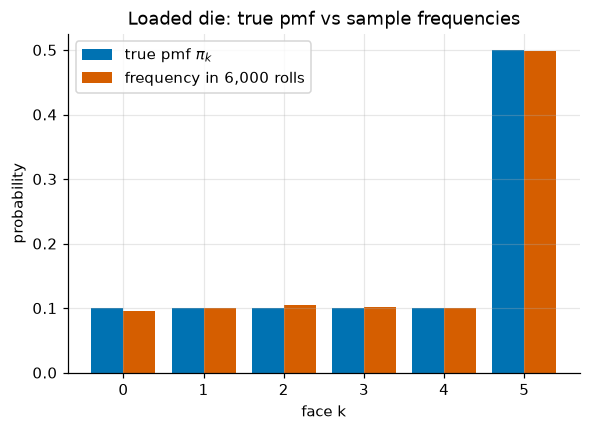

In [6]:
set_seed(0)
rolls = die.sample((6_000,))
freq = torch.bincount(rolls, minlength=6) / len(rolls)
faces = torch.arange(6)
plt.bar(faces - 0.2, probs, width=0.4, label="true pmf $\\pi_k$")
plt.bar(faces + 0.2, freq, width=0.4, label="frequency in 6,000 rolls")
plt.xlabel("face k")
plt.ylabel("probability")
plt.title("Loaded die: true pmf vs sample frequencies")
plt.legend()
plt.show()

With 6,000 rolls the bars nearly match; with 60 rolls (printed above) they are visibly off. Sample frequencies are noisy *estimates* of the true probabilities, and they get better with more samples. Section 2 makes "get better" precise.

### Continuous distributions: probability density

A continuous random variable, such as a measurement, can take any real value. The probability of hitting any *exact* value, like $1.2345678\ldots$, is zero, so a pmf makes no sense. Instead we use a **probability density function** (pdf) $p(x)$: probabilities are *areas* under the density,

$$P(a \le X \le b) = \int_a^b p(x)\, dx, \qquad \int_{-\infty}^{\infty} p(x)\, dx = 1.$$

The most important density is the **Gaussian** (or **normal**) distribution $\mathcal{N}(\mu, \sigma^2)$, with **mean** $\mu$ and **standard deviation** $\sigma > 0$:

$$p(x \mid \mu, \sigma) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\!\left(-\frac{(x - \mu)^2}{2\sigma^2}\right).$$

The bar in $p(x \mid \mu, \sigma)$ reads "given": the density of $x$ for given parameter values. The exponent is a parabola in $x$, so the density is a bell centred at $\mu$; $\sigma$ sets its width. The factor in front makes the total area exactly 1.

In [7]:
def gaussian_pdf(x, mu, sigma):
    """Gaussian density, written out from the formula."""
    return torch.exp(-((x - mu) ** 2) / (2 * sigma**2)) / math.sqrt(2 * math.pi * sigma**2)


xs = torch.linspace(-4, 4, 2001, dtype=torch.float64)  # shape (2001,)
for sigma in [1.0, 0.1]:
    dens = gaussian_pdf(xs, 0.0, sigma)
    area = torch.trapezoid(dens, xs).item()  # numerical integral of the density
    print(f"sigma = {sigma}: peak density {dens.max().item():.3f},  total area {area:.6f}")

print("matches Normal.log_prob:", torch.allclose(gaussian_pdf(xs, 0.0, 0.1), Normal(0.0, 0.1).log_prob(xs).exp()))

sigma = 1.0: peak density 0.399,  total area 0.999937
sigma = 0.1: peak density 3.989,  total area 1.000000
matches Normal.log_prob: True


With $\sigma = 0.1$ the peak density is about 3.99 — **a density can exceed 1**. That is not a contradiction: a density is probability *per unit length*, not a probability. A narrow bell must be tall so that its area is still 1. Only areas under the curve are probabilities.

Sampling from a Gaussian and drawing a **histogram** scaled to have area 1 (`density=True`) recovers the density curve:

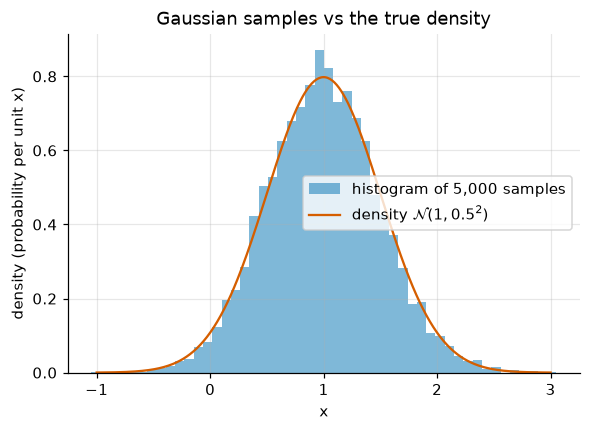

In [8]:
set_seed(0)
mu, sigma = 1.0, 0.5
samples = Normal(mu, sigma).sample((5_000,))  # shape (5000,)
grid = torch.linspace(-1, 3, 400)
plt.hist(samples, bins=50, density=True, alpha=0.5, label="histogram of 5,000 samples")
plt.plot(grid, gaussian_pdf(grid, mu, sigma), label="density $\\mathcal{N}(1, 0.5^2)$")
plt.xlabel("x")
plt.ylabel("density (probability per unit x)")
plt.title("Gaussian samples vs the true density")
plt.legend()
plt.show()

The histogram follows the curve. Each bar's *height* is a density, not a probability; its *area* (height × bar width) is the fraction of samples in that bin.

### Checkpoint 1.1

Compute the density of $\mathcal{N}(\mu = 2, \sigma = 3)$ at $x = 5$ **directly from the formula** (do not use `torch.distributions`), as a Python float `density_at_5`.

<details>
<summary><b>💡 Hint</b></summary>

$(x - \mu)^2 / (2\sigma^2) = 9 / 18 = 0.5$, so the answer is $e^{-0.5} / \sqrt{2\pi \cdot 9}$. Use `math.exp` and `math.sqrt`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check(isinstance(density_at_5, float), f"density_at_5 should be a Python float, got {type(density_at_5).__name__}")
check_close(density_at_5, Normal(2.0, 3.0).log_prob(torch.tensor(5.0)).exp().item(), "density_at_5", rtol=1e-5)
passed("Checkpoint 1.1")

## 2. Expectation and variance

The **expectation** (mean) of a random variable is its probability-weighted average value:

$$\mathbb{E}[X] = \sum_x x\, p(x) \quad \text{(discrete)}, \qquad \mathbb{E}[X] = \int x\, p(x)\, dx \quad \text{(continuous)}.$$

The **variance** measures spread: the expected squared distance from the mean $\mu = \mathbb{E}[X]$,

$$\operatorname{Var}[X] = \mathbb{E}\big[(X - \mu)^2\big],$$

and the **standard deviation** is $\sqrt{\operatorname{Var}[X]}$, which has the same units as $X$.

**Bernoulli, by hand.** $\mathbb{E}[X] = 0 \cdot (1-p) + 1 \cdot p = p$. And $\operatorname{Var}[X] = (0 - p)^2 (1 - p) + (1 - p)^2 p = p(1-p)\,[p + (1-p)] = p(1 - p)$.

**Gaussian (stated).** Doing the integrals gives $\mathbb{E}[X] = \mu$ and $\operatorname{Var}[X] = \sigma^2$; that is why the parameters have those names. We verify this numerically below rather than integrate by hand.

In [11]:
values = torch.arange(6, dtype=torch.float64)  # the die's faces 0..5, shape (6,)
probs64 = probs.double()
die_mean = (values * probs64).sum()
die_var = ((values - die_mean) ** 2 * probs64).sum()
print(f"loaded die: exact mean {die_mean.item():.4f}, exact variance {die_var.item():.4f}")
print(f"Bernoulli(0.3): mean {p}, variance p(1-p) = {p * (1 - p):.4f}")

# Gaussian: integrate x p(x) and (x - mu)^2 p(x) numerically on a wide grid.
xs = torch.linspace(-9, 11, 20_001, dtype=torch.float64)
dens = gaussian_pdf(xs, 1.0, 2.0)
g_mean = torch.trapezoid(xs * dens, xs)
g_var = torch.trapezoid((xs - g_mean) ** 2 * dens, xs)
print(f"N(1, 2^2) by numerical integration: mean {g_mean.item():.6f}, variance {g_var.item():.6f}")

loaded die: exact mean 3.5000, exact variance 3.2500
Bernoulli(0.3): mean 0.3, variance p(1-p) = 0.2100
N(1, 2^2) by numerical integration: mean 0.999999, variance 3.999938


Exact expectations need the true distribution, which in practice we rarely have. With samples $x_1, \ldots, x_n$ we **estimate** them with sample averages:

$$\bar{x} = \frac{1}{n}\sum_{i=1}^n x_i, \qquad s^2 = \frac{1}{n}\sum_{i=1}^n (x_i - \bar{x})^2.$$

In [12]:
set_seed(0)
for n in [10, 1_000, 100_000]:
    r = die.sample((n,)).double()
    print(f"n = {n:>7}: sample mean {r.mean().item():.4f}, sample variance {r.var(correction=0).item():.4f}")
print(f"exact:       mean {die_mean.item():.4f}, variance {die_var.item():.4f}")

n =      10: sample mean 4.0000, sample variance 2.0000
n =    1000: sample mean 3.4930, sample variance 3.2080
n =  100000: sample mean 3.5004, sample variance 3.2501
exact:       mean 3.5000, variance 3.2500


(`torch.var` divides by $n - 1$ by default; `correction=0` divides by $n$ as in our formula. Section 5 explains the difference.)

### The law of large numbers

The estimates above got closer to the truth as $n$ grew. The **law of large numbers** (stated without proof) says that for independent samples from the same distribution, the sample mean converges to the expectation as $n \to \infty$. Let us watch the **running mean** — the average of the first $n$ rolls, for every $n$ — in five independent experiments:

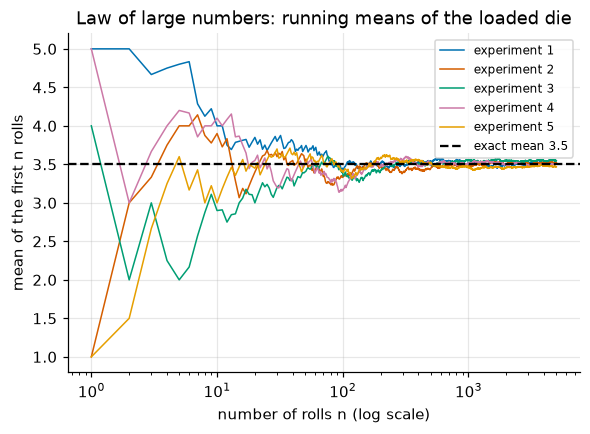

In [13]:
set_seed(0)
n_max = 5_000
ns = torch.arange(1, n_max + 1)
for run in range(5):
    r = die.sample((n_max,)).double()
    running_mean = torch.cumsum(r, dim=0) / ns  # shape (n_max,)
    plt.plot(ns, running_mean, lw=1, label=f"experiment {run + 1}")
plt.axhline(die_mean.item(), color="black", ls="--", label="exact mean 3.5")
plt.xscale("log")
plt.xlabel("number of rolls n (log scale)")
plt.ylabel("mean of the first n rolls")
plt.title("Law of large numbers: running means of the loaded die")
plt.legend(fontsize=8)
plt.show()

Early on, the five experiments disagree wildly; by a few thousand rolls they all hug the dashed line. Notice how slowly the funnel narrows: going from 50 to 5,000 rolls (100 times more data) shrinks the wobble by roughly a factor of 10, not 100.

That observation has a precise form, **stated here and verified experimentally in Exercise 4**: if the $x_i$ are independent with variance $\sigma^2$, the sample mean has standard deviation

$$\operatorname{SE}(\bar{x}) = \frac{\sigma}{\sqrt{n}},$$

called the **standard error**. Halving the error requires four times as much data. This $1/\sqrt{n}$ law will reappear whenever we estimate something from samples — including gradients from mini-batches in Chapter 3.

### Checkpoint 2.1

A spinner lands on the values $-1$, $0$, $2$ with probabilities $0.25$, $0.25$, $0.5$. Compute its exact mean `spinner_mean` and exact variance `spinner_var` as tensors, from the definitions.

<details>
<summary><b>💡 Hint</b></summary>

Mean: multiply values by probabilities elementwise and sum. Variance: the same weighted sum, applied to `(spinner_values - spinner_mean) ** 2`.

</details>

In [ ]:
spinner_values = torch.tensor([-1.0, 0.0, 2.0], dtype=torch.float64)
spinner_probs = torch.tensor([0.25, 0.25, 0.5], dtype=torch.float64)
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_close(spinner_mean, torch.tensor(0.75, dtype=torch.float64), "spinner_mean")
check_close(spinner_var, torch.tensor(1.6875, dtype=torch.float64), "spinner_var")
passed("Checkpoint 2.1")

## 3. Independence and the probability of a dataset

Two random variables are **independent** if knowing one tells you nothing about the other. Then their **joint probability** — the probability that both things happen — factorizes into a product: $P(X_1 = x_1, X_2 = x_2) = P(X_1 = x_1)\, P(X_2 = x_2)$.

A dataset $x_1, \ldots, x_N$ is usually modelled as **i.i.d.**: *independent* and *identically distributed* (every example comes from the same distribution $p$). Then the probability of the whole dataset is a product over examples:

$$p(x_1, \ldots, x_N) = \prod_{i=1}^N p(x_i).$$

For example, the probability of the sequence heads, heads, tails from a coin with $p = 0.3$ is $0.3 \times 0.3 \times 0.7 = 0.063$.

In [16]:
three = torch.tensor([1.0, 1.0, 0.0])
print("P(H, H, T) =", coin.log_prob(three).exp().prod().item())

P(H, H, T) = 0.06300000101327896


Independence is a modelling assumption, not a fact about data. Measurements from the same patient, or consecutive frames of a video, are not independent; i.i.d. is a useful simplification that this course will adopt unless stated otherwise.

### Products of many probabilities underflow

Each factor is at most 1, so the product shrinks exponentially with $N$. A `float32` cannot represent positive numbers below about $1.4 \times 10^{-45}$, and a `float64` below about $4.9 \times 10^{-324}$; anything smaller rounds to exactly `0.0` (**underflow**). Real datasets have thousands to millions of examples:

In [17]:
set_seed(0)
data = coin.sample((2_000,))  # 2,000 flips of the p = 0.3 coin
per_example = coin.log_prob(data).exp()  # shape (2000,): p(x_i) for every example

for N in [10, 100, 200, 1_000, 2_000]:
    prod32 = per_example[:N].float().prod().item()
    prod64 = per_example[:N].double().prod().item()
    log_sum = per_example[:N].double().log().sum().item()
    print(f"N = {N:>5}: product (float32) {prod32:.3e}   product (float64) {prod64:.3e}   sum of logs {log_sum:9.2f}")

N =    10: product (float32) 5.188e-03   product (float64) 5.188e-03   sum of logs     -5.26
N =   100: product (float32) 4.272e-29   product (float64) 4.272e-29   sum of logs    -65.32
N =   200: product (float32) 0.000e+00   product (float64) 7.821e-58   sum of logs   -131.49
N =  1000: product (float32) 0.000e+00   product (float64) 3.142e-268   sum of logs   -615.95
N =  2000: product (float32) 0.000e+00   product (float64) 0.000e+00   sum of logs  -1229.35


The `float32` product is already exactly zero by $N = 200$, and even `float64` gives zero by $N = 2{,}000$. Once the product is zero, every candidate model looks equally (im)probable and we cannot compare them.

The fix is to take logarithms. The log turns a product into a sum,

$$\log \prod_{i=1}^N p(x_i) = \sum_{i=1}^N \log p(x_i),$$

and a sum of $N$ moderate negative numbers (here each $\log p(x_i)$ is $\ln 0.3 \approx -1.20$ or $\ln 0.7 \approx -0.36$) is perfectly representable. Because $\log$ is strictly increasing, whichever model gives the data a larger probability also gives it a larger log-probability, so nothing is lost by comparing logs instead. This is why `torch.distributions` exposes `log_prob`, and why every loss in this course is built from log-probabilities.

### Checkpoint 3.1

Compute the log-probability `log_p_data` of the 2,000 flips in `data` under a coin with $p = 0.6$, as a sum of per-example log-probabilities. Use the formula $\log p(x) = x \log p + (1 - x)\log(1 - p)$, not `torch.distributions`.

<details>
<summary><b>💡 Hint</b></summary>

`data` is a tensor of 0s and 1s, so `data * math.log(0.6) + (1 - data) * math.log(0.4)` gives every example's log-probability at once. Then `.sum()`.

</details>

In [ ]:
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check(isinstance(log_p_data, torch.Tensor) and log_p_data.dim() == 0, "log_p_data should be a scalar (0-dimensional) tensor")
check(torch.isfinite(log_p_data).item(), "log_p_data is not finite: did you multiply probabilities before taking the log?")
check_close(log_p_data, Bernoulli(probs=torch.tensor(0.6)).log_prob(data).sum(), "log_p_data", rtol=1e-4)
passed("Checkpoint 3.1")

## 4. Likelihood

So far the parameter was fixed and we asked how probable various data are. Learning reverses the question: the **data are fixed** (we observed them) and the **parameter is unknown**. The **likelihood** is the probability of the observed data, viewed as a *function of the parameter*:

$$\mathcal{L}(p) = \prod_{i=1}^N p(x_i \mid p), \qquad \ell(p) = \log \mathcal{L}(p) = \sum_{i=1}^N \log p(x_i \mid p).$$

$\ell$ is the **log-likelihood**. For coin flips with $k$ heads among $N$ flips, every head contributes a factor $p$ and every tail a factor $1 - p$, so

$$\mathcal{L}(p) = p^k (1-p)^{N-k}, \qquad \ell(p) = k \log p + (N - k)\log(1 - p).$$

Here is a small dataset you can check by hand: 10 flips, 7 heads.

k = 7 heads out of N = 10


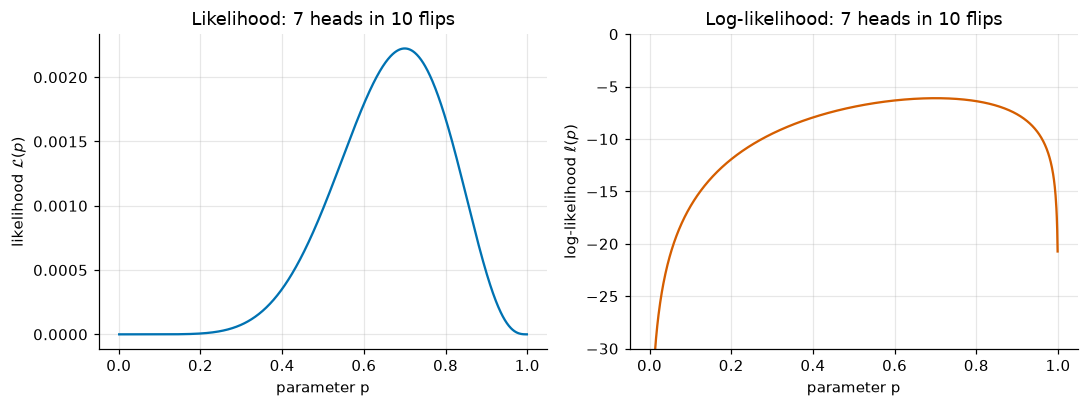

In [20]:
flips10 = torch.tensor([1, 0, 1, 1, 0, 1, 1, 1, 0, 1], dtype=torch.float64)  # shape (10,)
k, N = int(flips10.sum()), len(flips10)
print(f"k = {k} heads out of N = {N}")

p_grid = torch.linspace(0.001, 0.999, 999, dtype=torch.float64)  # candidate parameter values, shape (999,)
lik = p_grid**k * (1 - p_grid) ** (N - k)
loglik = k * torch.log(p_grid) + (N - k) * torch.log(1 - p_grid)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(p_grid, lik)
axes[0].set(xlabel="parameter p", ylabel="likelihood $\\mathcal{L}(p)$", title="Likelihood: 7 heads in 10 flips")
axes[1].plot(p_grid, loglik, color=COLORS[1])
axes[1].set(xlabel="parameter p", ylabel="log-likelihood $\\ell(p)$", title="Log-likelihood: 7 heads in 10 flips", ylim=(-30, 0))
plt.tight_layout()
plt.show()

Both curves peak at the same place, near $p = 0.7$, because $\log$ preserves order. The likelihood is zero at $p = 0$ and $p = 1$ (a coin that never or always lands heads cannot produce this mixed sequence), which the log-likelihood shows as a plunge towards $-\infty$.

**The likelihood is not a probability distribution over $p$.** It is a probability of the data, evaluated at different parameter values. Nothing forces its area over $p$ to be 1. Here the area is $\int_0^1 p^7(1-p)^3\,dp = \frac{7!\,3!}{11!} = \frac{1}{1320}$ (a standard integral, stated without proof):

In [21]:
area = torch.trapezoid(lik, p_grid).item()
print(f"area under the likelihood: {area:.6e}   (1/1320 = {1 / 1320:.6e})")

area under the likelihood: 7.575758e-04   (1/1320 = 7.575758e-04)


More data makes the likelihood more sharply peaked: more parameter values become implausible. To compare shapes, divide each likelihood by its maximum:

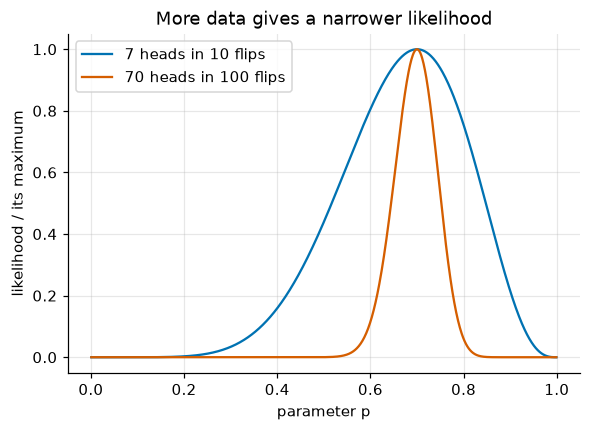

In [22]:
for k_, N_ in [(7, 10), (70, 100)]:
    ll = k_ * torch.log(p_grid) + (N_ - k_) * torch.log(1 - p_grid)
    plt.plot(p_grid, torch.exp(ll - ll.max()), label=f"{k_} heads in {N_} flips")
plt.xlabel("parameter p")
plt.ylabel("likelihood / its maximum")
plt.title("More data gives a narrower likelihood")
plt.legend()
plt.show()

Both curves peak at $p = 0.7$, but with 100 flips the curve is much narrower: values like $p = 0.5$ remain fairly plausible after 10 flips but not after 100. (The code computes $\exp(\ell - \max \ell)$ instead of $\mathcal{L}/\max\mathcal{L}$ directly, which is the same quantity but never forms the tiny raw product — the Section 3 lesson applied.)

## 5. Maximum likelihood estimation

**Maximum likelihood estimation** (MLE) picks the parameter value under which the observed data are most probable:

$$\hat{\theta}_{\text{MLE}} = \arg\max_\theta \ell(\theta),$$

where $\theta$ stands for whatever parameters the model has and "$\arg\max$" means "the value of $\theta$ that achieves the maximum". The hat marks an estimate computed from data.

### Bernoulli MLE

Use notebook 03's tool: at a maximum of a smooth function inside an interval, the derivative is zero. Differentiate $\ell(p) = k \log p + (N - k)\log(1-p)$:

$$\frac{d\ell}{dp} = \frac{k}{p} - \frac{N - k}{1 - p} = 0 \;\Longrightarrow\; k(1-p) = (N-k)p \;\Longrightarrow\; \hat{p} = \frac{k}{N}.$$

The second derivative $-k/p^2 - (N-k)/(1-p)^2$ is negative, so this is a maximum. The MLE is the **fraction of heads** — the sample mean of the 0/1 data. Two independent numerical checks:

In [23]:
p_hat = flips10.mean().item()
grid_best = p_grid[loglik.argmax()].item()
print(f"closed form k/N = {p_hat}   grid search argmax = {grid_best:.3f}")

# Gradient descent on the average negative log-likelihood, with the hand-derived gradient.
p_est, eta = 0.5, 0.05
for step in range(200):
    grad = -(k / p_est - (N - k) / (1 - p_est)) / N  # derivative of -ell(p)/N
    p_est -= eta * grad
print(f"gradient descent after 200 steps: p = {p_est:.6f}")

closed form k/N = 0.7   grid search argmax = 0.700
gradient descent after 200 steps: p = 0.700000


All three agree on $\hat{p} = 0.7$. Note the sign: gradient *descent* minimizes, so we minimized $-\ell/N$ (the average *negative* log-likelihood) to maximize $\ell$. Section 6 builds on exactly this.

### Gaussian MLE

For data $x_1, \ldots, x_N$ modelled as i.i.d. $\mathcal{N}(\mu, \sigma^2)$, the log-likelihood is the sum of the log-densities:

$$\ell(\mu, \sigma^2) = \sum_{i=1}^N \left[-\tfrac{1}{2}\log(2\pi\sigma^2) - \frac{(x_i - \mu)^2}{2\sigma^2}\right] = -\frac{N}{2}\log(2\pi\sigma^2) - \frac{1}{2\sigma^2}\sum_{i=1}^N (x_i - \mu)^2.$$

**Mean.** Only the last term depends on $\mu$. Its partial derivative is

$$\frac{\partial \ell}{\partial \mu} = \frac{1}{\sigma^2}\sum_{i=1}^N (x_i - \mu) = 0 \;\Longrightarrow\; \hat{\mu} = \frac{1}{N}\sum_{i=1}^N x_i = \bar{x},$$

the sample mean — whatever $\sigma$ is.

**Variance.** Treating $v = \sigma^2$ as the variable, $\partial \ell / \partial v = -\frac{N}{2v} + \frac{1}{2v^2}\sum_i (x_i - \mu)^2$. Setting this to zero at $\mu = \hat{\mu}$ gives

$$\hat{\sigma}^2 = \frac{1}{N}\sum_{i=1}^N (x_i - \bar{x})^2,$$

the average squared deviation, dividing by $N$. We verify both with a two-dimensional grid search:

In [24]:
set_seed(0)
x_obs = Normal(2.0, 1.5).sample((50,)).double()  # 50 observations, shape (50,)

mu_grid = torch.linspace(1.0, 3.0, 401, dtype=torch.float64)  # shape (401,)
sigma_grid = torch.linspace(0.8, 2.5, 341, dtype=torch.float64)  # shape (341,)
# Broadcast to a (401, 341, 50) tensor of log-densities, then sum over the data axis.
logdens = Normal(mu_grid[:, None, None], sigma_grid[None, :, None]).log_prob(x_obs[None, None, :])
ll_grid = logdens.sum(dim=-1)  # shape (401, 341)
i, j = divmod(ll_grid.argmax().item(), len(sigma_grid))

print(f"closed form: mu_hat = {x_obs.mean().item():.4f}, sigma_hat^2 = {x_obs.var(correction=0).item():.4f}")
print(f"grid search: mu     = {mu_grid[i].item():.4f}, sigma^2     = {sigma_grid[j].item() ** 2:.4f}")
print("(true values: mu = 2, sigma^2 = 2.25)")

closed form: mu_hat = 2.0732, sigma_hat^2 = 2.6066
grid search: mu     = 2.0750, sigma^2     = 2.6082
(true values: mu = 2, sigma^2 = 2.25)


The grid search agrees with the closed forms to within the grid spacing. Both estimates differ from the true values because 50 samples are a noisy view of the distribution — the MLE answers "which parameters best explain *this* data", not "what are the true parameters".

**Biased variance (stated, then checked).** The $1/N$ estimator is slightly too small on average: $\mathbb{E}[\hat{\sigma}^2] = \frac{N-1}{N}\sigma^2$. The reason is that $\bar{x}$ is fitted to the same data, so the data sit a little closer to $\bar{x}$ than to the true $\mu$. Dividing by $N - 1$ instead gives an unbiased estimate; that is what `torch.var` does by default. With tiny samples the difference is easy to see:

In [25]:
set_seed(0)
N_small, true_var = 5, 2.25
batches = Normal(2.0, 1.5).sample((200_000, N_small)).double()  # 200,000 datasets of 5 points each
print(f"average of 1/N estimates:     {batches.var(dim=1, correction=0).mean().item():.4f}")
print(f"(N-1)/N * true variance:      {(N_small - 1) / N_small * true_var:.4f}")
print(f"average of 1/(N-1) estimates: {batches.var(dim=1, correction=1).mean().item():.4f}   (true variance {true_var})")

average of 1/N estimates:     1.7999
(N-1)/N * true variance:      1.8000


average of 1/(N-1) estimates: 2.2499   (true variance 2.25)


For the large datasets of deep learning the factor $(N-1)/N$ is indistinguishable from 1, but you will meet both conventions (for example, batch normalization in Chapter 4 uses $1/N$).

### Checkpoint 5.1

Compute the Gaussian maximum likelihood estimates `mu_mle` and `var_mle` (a variance, not a standard deviation) for the data `x_check` below.

<details>
<summary><b>💡 Hint</b></summary>

The mean is `x_check.mean()`. For the variance either average the squared deviations yourself, or use `x_check.var(correction=0)` — the default `correction=1` divides by $N - 1$.

</details>

In [ ]:
x_check = torch.tensor([2.0, 4.0, 4.0, 4.0, 5.0, 5.0, 7.0, 9.0], dtype=torch.float64)
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_close(mu_mle, torch.tensor(5.0, dtype=torch.float64), "mu_mle")
check(
    not math.isclose(float(var_mle), 32 / 7, rel_tol=1e-6),
    "var_mle equals the 1/(N-1) estimate; the MLE divides by N",
)
check_close(var_mle, torch.tensor(4.0, dtype=torch.float64), "var_mle")
passed("Checkpoint 5.1")

## 6. From likelihood to loss

Optimizers minimize, so we flip the sign. The **negative log-likelihood** (NLL)

$$\text{NLL}(\theta) = -\ell(\theta) = -\sum_{i=1}^N \log p(x_i \mid \theta)$$

is a **loss**: small when the model finds the data probable, large when it finds it surprising. Minimizing the NLL is maximum likelihood estimation. Dividing by $N$ (the average NLL) does not move the minimum and makes the value comparable across dataset sizes.

### Gaussian noise gives squared error

Suppose we predict a target $y$ from an input $x$ with a model whose output is $\mu = f(x; \theta)$, and we assume the target is the prediction plus Gaussian noise of fixed standard deviation $\sigma$: $y_i \sim \mathcal{N}(f(x_i;\theta), \sigma^2)$. The NLL is

$$\text{NLL}(\theta) = \sum_{i=1}^N \left[\tfrac{1}{2}\log(2\pi\sigma^2) + \frac{(y_i - f(x_i;\theta))^2}{2\sigma^2}\right] = \frac{N}{2\sigma^2}\,\text{MSE}(\theta) + \frac{N}{2}\log(2\pi\sigma^2),$$

where $\text{MSE}(\theta) = \frac{1}{N}\sum_i (y_i - f(x_i;\theta))^2$ is the **mean squared error**. The last term does not depend on $\theta$, and $N/(2\sigma^2)$ is a positive constant. So **minimizing MSE is exactly maximum likelihood under Gaussian noise**, and the choice of $\sigma$ does not change the answer. Squared error is not arbitrary: it is what you get from assuming Gaussian noise. (A different noise assumption gives a different loss; the chapter problem set derives absolute error from the Laplace distribution.)

Let us check with the simplest model, a line through the origin, $f(x; w) = w x$:

In [28]:
set_seed(0)
N_reg, w_true, sigma_noise = 40, 1.7, 0.5
x_reg = torch.rand(N_reg, dtype=torch.float64) * 4 - 2  # inputs in [-2, 2], shape (40,)
y_reg = w_true * x_reg + sigma_noise * torch.randn(N_reg, dtype=torch.float64)  # shape (40,)

w_grid = torch.linspace(0.5, 3.0, 2501, dtype=torch.float64)  # candidate slopes, shape (2501,)
pred = w_grid[:, None] * x_reg[None, :]  # shape (2501, 40): every candidate's predictions
mse = ((y_reg[None, :] - pred) ** 2).mean(dim=1)  # shape (2501,)
nll = -Normal(pred, sigma_noise).log_prob(y_reg[None, :]).sum(dim=1)  # shape (2501,)

const = nll - N_reg / (2 * sigma_noise**2) * mse  # should be the same number for every w
print(f"argmin of MSE: w = {w_grid[mse.argmin()].item():.4f}")
print(f"argmin of NLL: w = {w_grid[nll.argmin()].item():.4f}")
print(f"NLL - N/(2 sigma^2) * MSE ranges over [{const.min().item():.10f}, {const.max().item():.10f}]")
print(f"(N/2) log(2 pi sigma^2) = {N_reg / 2 * math.log(2 * math.pi * sigma_noise**2):.10f}")

argmin of MSE: w = 1.6490
argmin of NLL: w = 1.6490
NLL - N/(2 sigma^2) * MSE ranges over [9.0316541058, 9.0316541058]
(N/2) log(2 pi sigma^2) = 9.0316541058


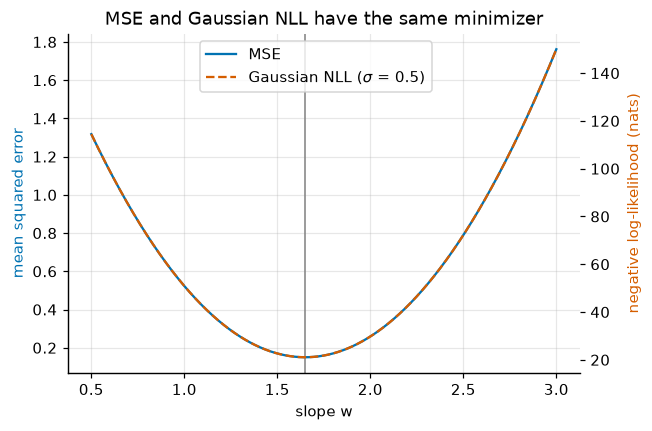

In [29]:
fig, ax1 = plt.subplots()
ax1.plot(w_grid, mse, label="MSE")
ax1.set_xlabel("slope w")
ax1.set_ylabel("mean squared error", color=COLORS[0])
ax2 = ax1.twinx()
ax2.plot(w_grid, nll, color=COLORS[1], ls="--", label="Gaussian NLL ($\\sigma$ = 0.5)")
ax2.set_ylabel("negative log-likelihood (nats)", color=COLORS[1])
ax2.grid(False)
ax1.axvline(w_grid[mse.argmin()].item(), color="gray", lw=1)
ax1.set_title("MSE and Gaussian NLL have the same minimizer")
fig.legend(loc="upper center", bbox_to_anchor=(0.5, 0.88))
plt.show()

On their own axes, the two curves lie exactly on top of each other: one is a shifted and rescaled copy of the other, so they share the minimizer (gray line). Notebook 06 uses this result to fit linear regression.

### Checkpoint 6.1

Using only `mse_val`, `N_reg`, and `sigma_noise`, compute the total Gaussian NLL `nll_from_mse` of the regression data at slope $w = 1.5$ via the formula $\frac{N}{2\sigma^2}\text{MSE} + \frac{N}{2}\log(2\pi\sigma^2)$.

<details>
<summary><b>💡 Hint</b></summary>

`N_reg / (2 * sigma_noise**2) * mse_val + N_reg / 2 * math.log(2 * math.pi * sigma_noise**2)`.

</details>

In [ ]:
mse_val = ((y_reg - 1.5 * x_reg) ** 2).mean().item()
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_close(nll_from_mse, -Normal(1.5 * x_reg, sigma_noise).log_prob(y_reg).sum().item(), "nll_from_mse", rtol=1e-6)
passed("Checkpoint 6.1")

### Bernoulli likelihood gives binary cross-entropy

Now suppose each target is a label $y_i \in \{0, 1\}$ and the model outputs a probability $\hat{p}_i$ that $y_i = 1$. Using the one-line Bernoulli pmf from Section 1, the NLL of one example is

$$-\log\big(\hat{p}_i^{\,y_i}(1-\hat{p}_i)^{1-y_i}\big) = -\big[y_i \log \hat{p}_i + (1 - y_i)\log(1 - \hat{p}_i)\big].$$

Averaged over examples, this is the **binary cross-entropy** loss. PyTorch provides it as `torch.nn.functional.binary_cross_entropy`:

In [32]:
y_lab = torch.tensor([1.0, 0.0, 1.0, 1.0])  # labels, shape (4,)
p_model = torch.tensor([0.9, 0.2, 0.6, 0.99])  # model's predicted P(y = 1), shape (4,)
by_hand = -(y_lab * torch.log(p_model) + (1 - y_lab) * torch.log(1 - p_model)).mean()
print("binary cross-entropy by hand:  ", by_hand.item())
print("F.binary_cross_entropy:        ", torch.nn.functional.binary_cross_entropy(p_model, y_lab).item())
print("Bernoulli NLL, averaged:       ", -Bernoulli(probs=p_model).log_prob(y_lab).mean().item())

binary cross-entropy by hand:   0.21234500408172607
F.binary_cross_entropy:         0.21234500408172607
Bernoulli NLL, averaged:        0.21234500408172607


All three agree. The confident correct prediction (0.99 for a 1) costs almost nothing; the hesitant 0.6 costs most. In notebook 09, $\hat{p}_i$ will be computed from an input by a model (logistic regression) and this loss will train it. Section 8 explains the name "cross-entropy".

## 7. Entropy

The **surprise** (or *information content*) of an outcome with probability $p$ is $-\log p$. A certain event ($p = 1$) has surprise 0; rare events have large surprise; and the surprises of independent events add, because their probabilities multiply. The NLL from Section 6 is exactly the total surprise of the data under the model.

With the natural log, surprise is measured in **nats**. With $\log_2$ it is measured in **bits**: one bit is the surprise of one fair coin flip ($-\log_2 0.5 = 1$), and $1 \text{ nat} = 1/\ln 2 \approx 1.44$ bits. This course uses natural logs (nats) throughout, as PyTorch does.

The **entropy** of a distribution is its *expected* surprise:

$$H(p) = \mathbb{E}_{X \sim p}\big[-\log p(X)\big] = -\sum_x p(x) \log p(x).$$

It measures how unpredictable $X$ is. Outcomes with $p(x) = 0$ never occur and should contribute nothing; formally $0 \log 0$ is undefined, so we use the convention $0 \cdot \log 0 = 0$, justified by the limit $p \log p \to 0$ as $p \to 0$:

In [33]:
for q in [1e-2, 1e-4, 1e-8, 1e-16]:
    print(f"p = {q:.0e}:  p * log(p) = {q * math.log(q):.3e}")
zero = torch.tensor(0.0)
print("naive 0 * log(0):          ", (zero * torch.log(zero)).item())
print("torch.special.xlogy(0, 0): ", torch.special.xlogy(zero, zero).item())

p = 1e-02:  p * log(p) = -4.605e-02
p = 1e-04:  p * log(p) = -9.210e-04
p = 1e-08:  p * log(p) = -1.842e-07
p = 1e-16:  p * log(p) = -3.684e-15
naive 0 * log(0):           nan
torch.special.xlogy(0, 0):  0.0


Computing $0 \cdot \log 0$ naively gives `nan` (because $0 \times (-\infty)$ is undefined in floating point). `torch.special.xlogy(x, y)` computes $x \log y$ and returns 0 whenever $x = 0$, which implements the convention.

### The entropy of a coin

For a Bernoulli($p$), $H(p) = -p\log p - (1-p)\log(1-p)$. Its derivative is $\log\frac{1-p}{p}$, which is zero only at $p = 1/2$, where $H = -\log\frac12 = \ln 2 \approx 0.693$ nats (exactly 1 bit).

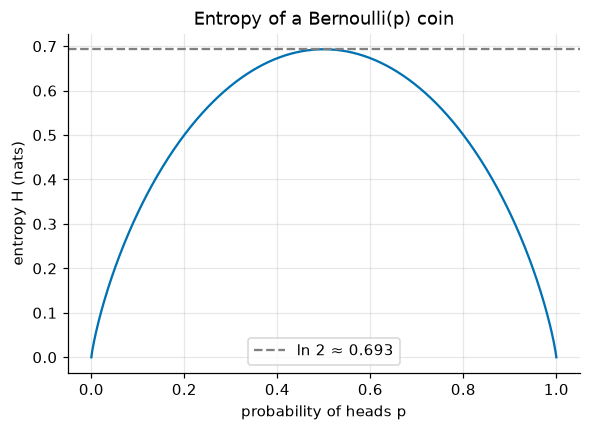

max entropy 0.693147 at p = 0.5; ln 2 = 0.693147


In [34]:
pp = torch.linspace(0, 1, 501, dtype=torch.float64)
H_coin = -(torch.special.xlogy(pp, pp) + torch.special.xlogy(1 - pp, 1 - pp))
plt.plot(pp, H_coin)
plt.axhline(math.log(2), color="gray", ls="--", label="ln 2 ≈ 0.693")
plt.xlabel("probability of heads p")
plt.ylabel("entropy H (nats)")
plt.title("Entropy of a Bernoulli(p) coin")
plt.legend()
plt.show()
print(f"max entropy {H_coin.max().item():.6f} at p = {pp[H_coin.argmax()].item()}; ln 2 = {math.log(2):.6f}")

A fair coin is the hardest to predict and has maximal entropy; a coin with $p = 0$ or $p = 1$ is perfectly predictable and has entropy 0. The curve is symmetric because swapping the labels heads/tails changes nothing about unpredictability.

For a categorical distribution on $K$ outcomes, the **uniform** distribution $\pi_k = 1/K$ has entropy $-\sum_k \frac1K \log \frac1K = \log K$, and this is the maximum possible (proved in Section 8). A quick numerical check on random distributions over $K = 6$ outcomes:

In [35]:
set_seed(0)
K = 6
random_dists = torch.distributions.Dirichlet(torch.ones(K, dtype=torch.float64)).sample((10_000,))  # shape (10000, 6), each row sums to 1
H_random = -torch.special.xlogy(random_dists, random_dists).sum(dim=1)  # shape (10000,)
print(f"largest entropy among 10,000 random distributions: {H_random.max().item():.4f}")
print(f"log K = ln 6 = {math.log(K):.4f}")
print(f"entropy of the loaded die: {die.entropy().item():.4f} (torch), "
      f"{-(probs64 * probs64.log()).sum().item():.4f} (by hand)")

largest entropy among 10,000 random distributions: 1.7828
log K = ln 6 = 1.7918
entropy of the loaded die: 1.4979 (torch), 1.4979 (by hand)


(A **Dirichlet** distribution generates random probability vectors; we only use it here as a source of test cases.) No random distribution exceeds $\ln 6 \approx 1.79$, and the loaded die, being more predictable than a fair one, has lower entropy.

### Checkpoint 7.1

Compute the entropy in nats of the probability vector `pk` below as a scalar tensor `H_pk`. It contains a zero, so handle $0 \log 0 = 0$.

<details>
<summary><b>💡 Hint</b></summary>

`torch.special.xlogy(pk, pk)` gives $p_k \log p_k$ with the convention built in. By hand: $-(0.5\ln 0.5 + 2 \times 0.25 \ln 0.25) = 1.5 \ln 2$.

</details>

In [ ]:
pk = torch.tensor([0.5, 0.25, 0.25, 0.0], dtype=torch.float64)
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check(isinstance(H_pk, torch.Tensor) and H_pk.dim() == 0, "H_pk should be a scalar tensor")
check(not torch.isnan(H_pk).item(), "H_pk is nan: the zero entry must contribute 0, not 0 * log(0)")
check_close(H_pk, torch.tensor(1.5 * math.log(2), dtype=torch.float64), "H_pk")
passed("Checkpoint 7.1")

## 8. Cross-entropy and KL divergence

Suppose outcomes really come from a distribution $p$, but we predict them with a model $q$. Our average surprise is the **cross-entropy**

$$H(p, q) = \mathbb{E}_{X \sim p}\big[-\log q(X)\big] = -\sum_x p(x) \log q(x).$$

How much worse is that than the best possible, $H(p)$? The difference is the **Kullback–Leibler (KL) divergence**:

$$\mathrm{KL}(p \,\|\, q) = H(p, q) - H(p) = \sum_x p(x) \log\frac{p(x)}{q(x)}.$$

**Gibbs' inequality:** $\mathrm{KL}(p\,\|\,q) \ge 0$, with equality only when $q = p$. The proof is short. Use $\log t \le t - 1$ (true for all $t > 0$, with equality only at $t = 1$: the line $t - 1$ is tangent to $\log t$ at $t = 1$, and $\log$ curves downward). Summing only over outcomes with $p(x) > 0$,

$$-\mathrm{KL}(p\,\|\,q) = \sum_x p(x)\log\frac{q(x)}{p(x)} \le \sum_x p(x)\left(\frac{q(x)}{p(x)} - 1\right) = \sum_{x:\,p(x)>0} q(x) - 1 \le 0.$$

Equality needs $q(x)/p(x) = 1$ wherever $p(x) > 0$, that is, $q = p$. So **cross-entropy is never smaller than entropy**, and KL behaves like a "distance" from $p$ to $q$ — with a catch shown below.

In [38]:
p_ex = torch.tensor([0.5, 0.3, 0.2], dtype=torch.float64)
q_ex = torch.tensor([0.4, 0.4, 0.2], dtype=torch.float64)
H_p = -(p_ex * p_ex.log()).sum()
H_pq = -(p_ex * q_ex.log()).sum()
kl_hand = (p_ex * (p_ex / q_ex).log()).sum()
kl_torch = torch.distributions.kl_divergence(Categorical(probs=p_ex), Categorical(probs=q_ex))
print(f"H(p) = {H_p.item():.6f}   H(p, q) = {H_pq.item():.6f}   H(p, q) - H(p) = {(H_pq - H_p).item():.6f}")
print(f"KL(p || q) by hand = {kl_hand.item():.6f}   torch.distributions.kl_divergence = {kl_torch.item():.6f}")

H(p) = 1.029653   H(p, q) = 1.054920   H(p, q) - H(p) = 0.025267
KL(p || q) by hand = 0.025267   torch.distributions.kl_divergence = 0.025267


Now Gibbs' inequality on many random pairs of distributions, plus the equality case:

In [39]:
set_seed(0)
dirichlet = torch.distributions.Dirichlet(torch.ones(K, dtype=torch.float64))
P, Q = dirichlet.sample((10_000,)), dirichlet.sample((10_000,))  # each shape (10000, 6)
kl_pairs = (P * (P / Q).log()).sum(dim=1)  # shape (10000,)
print(f"smallest KL over 10,000 random pairs: {kl_pairs.min().item():.6f}")
print(f"KL(p || p) for the first 5 rows of P: {(P[:5] * (P[:5] / P[:5]).log()).sum(dim=1).tolist()}")

smallest KL over 10,000 random pairs: 0.018215
KL(p || p) for the first 5 rows of P: [0.0, 0.0, 0.0, 0.0, 0.0]


Gibbs' inequality also proves the claim from Section 7. Against the uniform distribution $u_k = 1/K$: $\mathrm{KL}(p\,\|\,u) = \sum_k p_k \log(K p_k) = \log K - H(p) \ge 0$, so $H(p) \le \log K$.

### KL is not symmetric

A true distance satisfies $d(p, q) = d(q, p)$. KL does not:

In [40]:
p_a = torch.tensor([0.9, 0.1], dtype=torch.float64)
q_a = torch.tensor([0.5, 0.5], dtype=torch.float64)
kl_pq = (p_a * (p_a / q_a).log()).sum().item()
kl_qp = (q_a * (q_a / p_a).log()).sum().item()
print(f"KL(p || q) = {kl_pq:.4f}    KL(q || p) = {kl_qp:.4f}")

KL(p || q) = 0.3681    KL(q || p) = 0.5108


The two directions differ by a factor of about 1.4. $\mathrm{KL}(p\,\|\,q)$ averages over outcomes drawn from $p$, so it heavily penalizes $q$ for assigning low probability to things $p$ makes common. That is why KL is called a *divergence*, not a distance, and why the order of arguments always matters.

### Zeros

Two conventions follow from the definition:

- If $p(x) = 0$, the term $p(x)\log\frac{p(x)}{q(x)}$ is 0 (outcomes that never happen cost nothing), by $0 \log 0 = 0$.
- If $p(x) > 0$ but $q(x) = 0$, the term is $+\infty$: the model says an outcome that does happen is impossible, which is infinitely surprising. Then $H(p, q) = \mathrm{KL}(p\,\|\,q) = \infty$.

In [41]:
p_z = torch.tensor([0.5, 0.5, 0.0])
q_z = torch.tensor([0.5, 0.25, 0.25])
print("KL(p || q), p has a zero:      ", torch.distributions.kl_divergence(Categorical(probs=p_z), Categorical(probs=q_z)).item())
print("KL(q || p), p is zero where q>0:", torch.distributions.kl_divergence(Categorical(probs=q_z), Categorical(probs=p_z)).item())

KL(p || q), p has a zero:       0.3465735912322998
KL(q || p), p is zero where q>0: inf


PyTorch applies both conventions: the first KL is finite ($0.5 \ln 1 + 0.5 \ln 2 = 0.5\ln 2 \approx 0.347$), the second is infinite. Exercise 2 asks you to implement them yourself. In practice this is one reason classifiers never output a probability of exactly 0: one surprising example would make the loss infinite.

### Maximum likelihood = minimum cross-entropy = minimum KL

Here is the key connection. Take a dataset of $N$ labels $y_1, \ldots, y_N \in \{0, \ldots, K-1\}$ and a categorical model $\mathbf{q} = (q_0, \ldots, q_{K-1})$. Let $N_k$ be the number of labels equal to $k$, and $\hat{p}_k = N_k / N$ the **empirical distribution** — the label frequencies. Group the terms of the average NLL by label value:

$$\frac{1}{N}\text{NLL}(\mathbf{q}) = -\frac{1}{N}\sum_{i=1}^N \log q_{y_i} = -\frac{1}{N}\sum_{k} N_k \log q_k = -\sum_k \hat{p}_k \log q_k = H(\hat{p}, \mathbf{q}).$$

**The average NLL is the cross-entropy from the empirical distribution to the model.** That is where the name "cross-entropy loss" comes from. Furthermore, $H(\hat{p}, \mathbf{q}) = H(\hat{p}) + \mathrm{KL}(\hat{p}\,\|\,\mathbf{q})$, and $H(\hat{p})$ depends only on the data. So

$$\text{maximize likelihood} \iff \text{minimize } H(\hat{p}, \mathbf{q}) \iff \text{minimize } \mathrm{KL}(\hat{p}\,\|\,\mathbf{q}),$$

and by Gibbs' inequality the minimum is at $\mathbf{q} = \hat{p}$: **the categorical MLE is the vector of label frequencies**, generalizing $\hat{p} = k/N$ for the coin. (The same identity holds for any model, including the neural network classifiers of later chapters, where it is applied to labels given inputs; the empirical distribution is then the best the model could possibly do on the training data.)

In [42]:
set_seed(0)
labels = die.sample((500,))  # 500 labels from the loaded die, shape (500,)
p_emp = torch.bincount(labels, minlength=K).double() / len(labels)  # empirical distribution, shape (6,)
q_model = torch.tensor([0.2, 0.2, 0.1, 0.1, 0.1, 0.3], dtype=torch.float64)  # some model


def avg_nll(q):
    return -q.log()[labels].mean()  # look up log q_{y_i} for every label, then average


def cross_ent(p_, q_):
    return -(torch.special.xlogy(p_, q_)).sum()


print(f"average NLL of the model:       {avg_nll(q_model).item():.6f}")
print(f"cross-entropy H(p_emp, q_model): {cross_ent(p_emp, q_model).item():.6f}")
print(f"H(p_emp) + KL(p_emp || q_model): {(cross_ent(p_emp, p_emp) + (p_emp * (p_emp / q_model).log()).sum()).item():.6f}")

# The MLE should be p_emp: compare against many random models.
random_models = dirichlet.sample((20_000,))  # shape (20000, 6)
nll_random = -(random_models.log()[:, labels]).mean(dim=1)  # shape (20000,)
print(f"\nempirical frequencies p_emp:          {[round(v, 3) for v in p_emp.tolist()]}")
print(f"average NLL at p_emp:                 {avg_nll(p_emp).item():.6f}  (= H(p_emp) = {cross_ent(p_emp, p_emp).item():.6f})")
print(f"best average NLL of 20,000 random q:  {nll_random.min().item():.6f}")

average NLL of the model:       1.618808
cross-entropy H(p_emp, q_model): 1.618808
H(p_emp) + KL(p_emp || q_model): 1.618808

empirical frequencies p_emp:          [0.084, 0.11, 0.098, 0.1, 0.108, 0.5]
average NLL at p_emp:                 1.495696  (= H(p_emp) = 1.495696)
best average NLL of 20,000 random q:  1.506420


The first three numbers are identical, confirming the decomposition. The empirical frequencies achieve an average NLL equal to the entropy $H(\hat{p})$, and none of 20,000 random models does better, as Gibbs' inequality guarantees.

### Checkpoint 8.1

For `p8` and `q8` below, compute the entropy `H_p8`, the cross-entropy `H_p8_q8` $= H(p, q)$, and the KL divergence `KL_p8_q8` $= \mathrm{KL}(p\,\|\,q)$ directly from the definitions (each a scalar tensor).

<details>
<summary><b>💡 Hint</b></summary>

Every probability here is a power of 1/2, so every log is a multiple of $\ln 2$. The answers are $1.5\ln 2$, $1.75\ln 2$, and $0.25\ln 2$. In code: `-(p8 * p8.log()).sum()`, `-(p8 * q8.log()).sum()`, `(p8 * (p8 / q8).log()).sum()`.

</details>

In [ ]:
p8 = torch.tensor([0.25, 0.25, 0.5], dtype=torch.float64)
q8 = torch.tensor([0.5, 0.25, 0.25], dtype=torch.float64)
# YOUR CODE HERE
raise NotImplementedError

In [ ]:
check_close(H_p8, torch.tensor(1.5 * math.log(2), dtype=torch.float64), "H_p8")
check_close(H_p8_q8, torch.tensor(1.75 * math.log(2), dtype=torch.float64), "H_p8_q8")
check_close(KL_p8_q8, torch.tensor(0.25 * math.log(2), dtype=torch.float64), "KL_p8_q8")
check_close(H_p8_q8 - H_p8, KL_p8_q8, "H(p, q) - H(p)")
passed("Checkpoint 8.1")

## Exercises

### Exercise 1 (modify): how much does the MLE wobble?

The cell below repeats an experiment 2,000 times: flip a coin with true $p = 0.3$ exactly `n` times and compute the MLE $\hat{p}$ (the fraction of heads). It plots the spread of the 2,000 estimates.

Run it with `n = 20`, then change `n` to `200` and run it again. How do the centre and the spread of the estimates change? By roughly what factor does the standard deviation shrink? Write your answer in the markdown cell below.

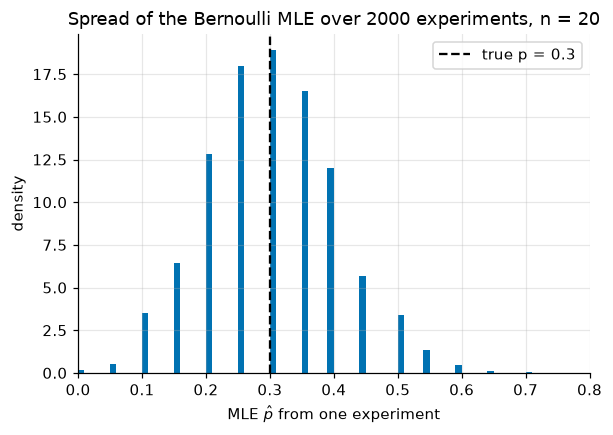

n = 20: mean of estimates 0.3004, standard deviation 0.1040


In [45]:
n = 20  # flips per experiment
repeats = 2_000
p_true = 0.3

gen = torch.Generator().manual_seed(0)
experiments = (torch.rand(repeats, n, generator=gen, dtype=torch.float64) < p_true).double()  # shape (repeats, n)
p_hats = experiments.mean(dim=1)  # one MLE per experiment, shape (repeats,)

plt.hist(p_hats, bins=torch.linspace(0, 0.8, 81).tolist(), density=True)
plt.axvline(p_true, color="black", ls="--", label="true p = 0.3")
plt.xlim(0, 0.8)
plt.xlabel("MLE $\\hat{p}$ from one experiment")
plt.ylabel("density")
plt.title(f"Spread of the Bernoulli MLE over {repeats} experiments, n = {n}")
plt.legend()
plt.show()
print(f"n = {n}: mean of estimates {p_hats.mean().item():.4f}, standard deviation {p_hats.std().item():.4f}")

*Your answer:*

### Exercise 2 (implement): cross-entropy and KL divergence

Write `cross_entropy(p, q)` and `kl_divergence(p, q)` for probability vectors `p` and `q` (1-D tensors of the same length, each summing to 1). Return scalar tensors. Requirements:

- Terms with $p_i = 0$ contribute 0, even if $q_i = 0$ too.
- If $q_i = 0$ for some $i$ with $p_i > 0$, return `inf`.
- Do not use `torch.distributions` (the check compares against it).

<details>
<summary><b>💡 Hint</b></summary>

Keep only the entries where `p > 0`: `mask = p > 0`, then work with `p[mask]` and `q[mask]`. Where $q_i = 0$, `q[mask].log()` is `-inf`, and multiplying by a positive $p_i$ gives `-inf`, so the cross-entropy becomes `+inf` automatically. For KL, use $\sum p_i(\log p_i - \log q_i)$ on the masked entries. (`torch.special.xlogy` is an alternative for the cross-entropy.)

</details>

In [ ]:
def cross_entropy(p, q):
    """H(p, q) = -sum_i p_i log q_i, with 0 log 0 = 0. Shapes: p, q (K,) -> scalar."""
    # YOUR CODE HERE
    raise NotImplementedError


def kl_divergence(p, q):
    """KL(p || q) = sum_i p_i log(p_i / q_i), with 0 log 0 = 0. Shapes: p, q (K,) -> scalar."""
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
half = torch.tensor([0.5, 0.5], dtype=torch.float64)
quarter = torch.tensor([0.25, 0.75], dtype=torch.float64)
check_close(cross_entropy(half, quarter), torch.tensor(-0.5 * math.log(0.25) - 0.5 * math.log(0.75), dtype=torch.float64), "cross_entropy([.5,.5], [.25,.75])")
check_close(kl_divergence(half, half), torch.tensor(0.0, dtype=torch.float64), "kl_divergence(p, p)")
check_close(cross_entropy(half, half), torch.tensor(math.log(2), dtype=torch.float64), "cross_entropy(p, p) = H(p)")

gen_check = torch.Generator().manual_seed(1)
for _ in range(20):
    a = torch.rand(5, generator=gen_check, dtype=torch.float64) + 0.01
    b = torch.rand(5, generator=gen_check, dtype=torch.float64) + 0.01
    a, b = a / a.sum(), b / b.sum()
    reference = torch.distributions.kl_divergence(Categorical(probs=a), Categorical(probs=b))
    check_close(kl_divergence(a, b), reference, "kl_divergence on random vectors")
    check_close(cross_entropy(a, b) - cross_entropy(a, a), kl_divergence(a, b), "H(p, q) - H(p)")

p_zero = torch.tensor([0.5, 0.5, 0.0], dtype=torch.float64)
q_zero = torch.tensor([0.5, 0.5, 0.0], dtype=torch.float64)
check(torch.isfinite(kl_divergence(p_zero, q_zero)).item(), "p_i = 0 = q_i must contribute 0, not nan")
check_close(kl_divergence(p_zero, q_zero), torch.tensor(0.0, dtype=torch.float64), "KL with shared zeros")
check_close(cross_entropy(p_zero, q_zero), torch.tensor(math.log(2), dtype=torch.float64), "cross-entropy with shared zeros")
q_bad = torch.tensor([1.0, 0.0, 0.0], dtype=torch.float64)
check(kl_divergence(p_zero, q_bad).item() == math.inf, "KL must be +inf when q_i = 0 < p_i")
check(cross_entropy(p_zero, q_bad).item() == math.inf, "cross-entropy must be +inf when q_i = 0 < p_i")
passed("Exercise 2")

### Exercise 3 (debug): a log-likelihood that breaks on real datasets

`gaussian_log_likelihood(x, mu, sigma)` should return $\sum_i \log p(x_i \mid \mu, \sigma)$ for data `x` (shape `(N,)`) under $\mathcal{N}(\mu, \sigma^2)$. The buggy version below seems fine on a few points with $\sigma = 1$, but returns `-inf` on a dataset of 5,000 points, and gives wrong values whenever $\sigma \ne 1$. It has **two** bugs. Find and fix both.

<details>
<summary><b>💡 Hint</b></summary>

Bug 1: multiplying 5,000 densities underflows to 0 (Section 3); sum log-densities instead. Bug 2: compare the normalizing constant with the Gaussian formula in Section 1 — is it $\sqrt{2\pi\sigma}$ or $\sqrt{2\pi\sigma^2}$? Both bugs vanish when $\sigma = 1$ and $N$ is small, which is why a quick test missed them. The log-density is $-\frac12\log(2\pi\sigma^2) - \frac{(x-\mu)^2}{2\sigma^2}$.

</details>

In [ ]:
def gaussian_log_likelihood(x, mu, sigma):
    # Buggy version:
    #     densities = torch.exp(-((x - mu) ** 2) / (2 * sigma**2)) / torch.sqrt(torch.tensor(2 * math.pi * sigma))
    #     return torch.log(torch.prod(densities))
    # YOUR CODE HERE
    raise NotImplementedError

In [ ]:
x_few = torch.tensor([0.1, -0.4, 0.3], dtype=torch.float64)
check_close(gaussian_log_likelihood(x_few, 0.0, 1.0), Normal(0.0, 1.0).log_prob(x_few).sum(), "3 points, sigma = 1")
check_close(gaussian_log_likelihood(x_few, 0.5, 2.0), Normal(0.5, 2.0).log_prob(x_few).sum(), "3 points, sigma = 2")
x_many = 1.0 + 3.0 * torch.randn(5_000, generator=torch.Generator().manual_seed(0), dtype=torch.float64)  # shape (5000,)
result = gaussian_log_likelihood(x_many, 1.0, 3.0)
check(torch.isfinite(result).item(), f"log-likelihood of 5,000 points is {result.item()}; it should be finite")
check_close(result, Normal(1.0, 3.0).log_prob(x_many).sum(), "5,000 points, sigma = 3")
passed("Exercise 3")

### Exercise 4 (investigate): how fast does the MLE improve with more data?

Section 2 stated that a sample mean has standard deviation $\sigma/\sqrt{n}$. The Bernoulli MLE $\hat{p}$ is a sample mean of 0/1 values with variance $p(1-p)$, so the claim predicts

$$\operatorname{sd}(\hat{p}) = \sqrt{\frac{p(1-p)}{n}} \propto n^{-1/2}.$$

On a log-log plot, $\log \operatorname{sd} = -\tfrac12 \log n + \text{const}$ is a straight line with slope $-1/2$. Test this:

1. Run the scaffold. It repeats the Exercise 1 experiment for several values of `n`, measures the standard deviation of $\hat{p}$ across repeats, plots it on log-log axes, and fits a straight line.
2. Is the measured slope close to $-1/2$? Do the measurements match the theoretical curve?
3. How many flips would you need to get the standard deviation down to 0.01? Write your conclusion below.

<details>
<summary><b>💡 Hint</b></summary>

The fitted slope is the exponent $a$ in $\operatorname{sd} \approx C n^{a}$. For the last question, solve $\sqrt{p(1-p)/n} = 0.01$ for $n$.

</details>

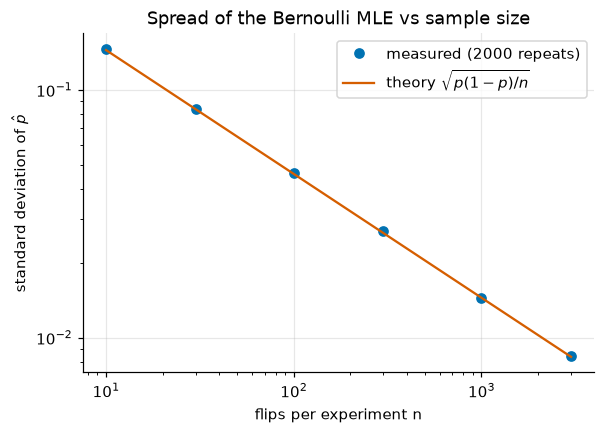

fitted slope on log-log axes: -0.501
n =    10: measured sd 0.1466   theory 0.1449   ratio 1.012
n =    30: measured sd 0.0841   theory 0.0837   ratio 1.005
n =   100: measured sd 0.0463   theory 0.0458   ratio 1.010
n =   300: measured sd 0.0269   theory 0.0265   ratio 1.017
n =  1000: measured sd 0.0145   theory 0.0145   ratio 0.998
n =  3000: measured sd 0.0084   theory 0.0084   ratio 1.008


In [50]:
p_true = 0.3
repeats = 2_000
sizes = [10, 30, 100, 300, 1_000, 3_000]
gen = torch.Generator().manual_seed(0)

measured_sd = []
for n in sizes:
    p_hats = (torch.rand(repeats, n, generator=gen, dtype=torch.float64) < p_true).double().mean(dim=1)  # shape (repeats,)
    measured_sd.append(p_hats.std().item())

log_n = torch.log(torch.tensor(sizes, dtype=torch.float64))
log_sd = torch.log(torch.tensor(measured_sd, dtype=torch.float64))
A = torch.stack([log_n, torch.ones_like(log_n)], dim=1)  # (len(sizes), 2) design matrix for a line
slope, intercept = torch.linalg.lstsq(A, log_sd[:, None]).solution.squeeze(1).tolist()

theory = [math.sqrt(p_true * (1 - p_true) / n) for n in sizes]
plt.loglog(sizes, measured_sd, "o", label=f"measured ({repeats} repeats)")
plt.loglog(sizes, theory, "-", label="theory $\\sqrt{p(1-p)/n}$")
plt.xlabel("flips per experiment n")
plt.ylabel("standard deviation of $\\hat{p}$")
plt.title("Spread of the Bernoulli MLE vs sample size")
plt.legend()
plt.show()

print(f"fitted slope on log-log axes: {slope:.3f}")
for n, m, t in zip(sizes, measured_sd, theory):
    print(f"n = {n:>5}: measured sd {m:.4f}   theory {t:.4f}   ratio {m / t:.3f}")

*Your conclusion:*

## Summary and what's next

- A distribution assigns probability mass (discrete) or density (continuous) to values. Densities can exceed 1; only their areas are probabilities.
- Expectations and variances can be estimated by sample averages, whose error shrinks like $1/\sqrt{n}$.
- The probability of an i.i.d. dataset is a product, which underflows; we work with sums of log-probabilities instead.
- The **likelihood** is the probability of fixed data as a function of the parameters (not a distribution over them). **Maximum likelihood** chooses the parameters that make the data most probable: the sample mean for a coin, the sample mean and $1/N$ variance for a Gaussian, the label frequencies for a categorical.
- The **negative log-likelihood** is a loss. Gaussian noise gives mean squared error; Bernoulli labels give binary cross-entropy.
- **Entropy** is expected surprise. **Cross-entropy** $H(p, q) = H(p) + \mathrm{KL}(p\,\|\,q)$, and $\mathrm{KL} \ge 0$. Minimizing the average NLL is minimizing the cross-entropy, and the KL divergence, from the data's empirical distribution to the model.

We can now *write* a loss for a model, and notebook 03 tells us how to minimize it: follow the gradient. But every gradient so far was derived by hand. For a model with millions of parameters and many layers, hand derivation is tedious and error-prone, and finite differences are far too slow. Notebook 05 introduces **autograd**, PyTorch's system for computing exact gradients of any computation automatically.